# 03 — Optimización, ensamble y selección final (E3)
**AppleVision Chile — MLY1101**

> **Advertencia.** 38 filas, 4 manzanas, etiqueta simulada (semáforo sin calibre). Optuna elige hiperparámetros mirando los mismos pliegues leave-one-id-out con los que se reporta el F1, así que **el F1 de los modelos optimizados está inflado** respecto a datos nuevos. La comparación sirve para ver el flujo de trabajo, no para afirmar que un modelo es mejor.

## 1. Datos

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
import mlflow, optuna
from pathlib import Path
from sklearn.model_selection import LeaveOneGroupOut, learning_curve
from src.ml.features import preparar, FEATURES_SUPERVISADO
from src.ml import train, evaluate, optimize
sns.set_theme(style='whitegrid')
FIG = Path('../reports/figuras_ml'); FIG.mkdir(parents=True, exist_ok=True)

df, X, y, grupos = preparar()
print('Features:', FEATURES_SUPERVISADO, '| filas:', len(df), '| apto:', y.value_counts().to_dict())

Features: ['area_px', 'diametro_mm_est', 'valor'] | filas: 38 | apto: {0: 29, 1: 9}


## 2. Modelos base (referencia)

In [2]:
resultados, preds = {}, {}
def evaluar(nombre, modelo):
    preds[nombre] = train.predecir_por_grupos(modelo, X, y, grupos)
    resultados[nombre] = evaluate.metricas_clasificacion(y, preds[nombre])

base = train.crear_modelos(y)
evaluar('RF base', base['random_forest'])
evaluar('XGBoost base', base['xgboost'])
pd.DataFrame(resultados).T.round(3)

,accuracy,precision,recall,f1
RF base,0.447,0.125,0.222,0.160
XGBoost base,0.500,0.083,0.111,0.095


## 3. Optuna (25 trials por modelo, leave-one-id-out)
Cada trial se registra como run anidado en MLflow (`mlflow.db`).

In [3]:
N_TRIALS = 25
estudios = {}
for nombre in ['random_forest', 'xgboost']:
    estudios[nombre] = optimize.optimizar(nombre, X, y, grupos, n_trials=N_TRIALS)
    print(nombre, '| mejor F1 CV:', round(estudios[nombre].best_value, 3), '|', estudios[nombre].best_params)

random_forest | mejor F1 CV: 0.24 | {'n_estimators': 400, 'max_depth': 2, 'min_samples_split': 5}


xgboost | mejor F1 CV: 0.133 | {'max_depth': 2, 'learning_rate': 0.07282870067862052, 'n_estimators': 50}


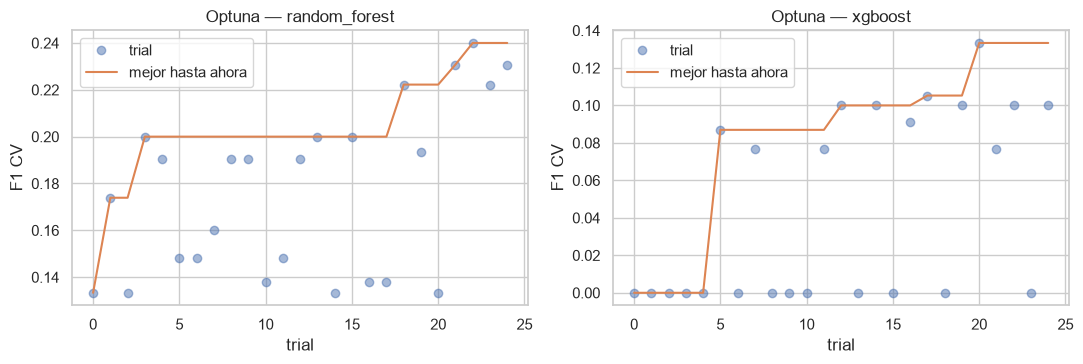

,random_forest,xgboost
min_samples_split,0.658,NaN
max_depth,0.280,0.501
n_estimators,0.062,0.008
learning_rate,NaN,0.491


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (nombre, est) in zip(axs, estudios.items()):
    vals = [t.value for t in est.trials]
    ax.plot(vals, 'o', alpha=.5, label='trial'); ax.plot(np.maximum.accumulate(vals), '-', label='mejor hasta ahora')
    ax.set_title(f'Optuna — {nombre}'); ax.set_xlabel('trial'); ax.set_ylabel('F1 CV'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'optuna_historia.png', dpi=120); plt.show()

imp_hp = {n: optuna.importance.get_param_importances(e) for n, e in estudios.items()}
pd.DataFrame(imp_hp).round(3)

## 4. Modelos optimizados y ensamble (Voting)

In [5]:
bp_rf, bp_xgb = estudios['random_forest'].best_params, estudios['xgboost'].best_params
evaluar('RF optimizado', optimize.construir('random_forest', bp_rf, y))
evaluar('XGBoost optimizado', optimize.construir('xgboost', bp_xgb, y))
evaluar('Voting soft (RF+XGB opt.)', optimize.crear_ensamble(bp_rf, bp_xgb, y, 'soft'))
evaluar('Voting hard (RF+XGB opt.)', optimize.crear_ensamble(bp_rf, bp_xgb, y, 'hard'))
tabla = pd.DataFrame(resultados).T.round(3)
tabla

,accuracy,precision,recall,f1
RF base,0.447,0.125,0.222,0.160
XGBoost base,0.500,0.083,0.111,0.095
RF optimizado,0.500,0.188,0.333,0.240
XGBoost optimizado,0.316,0.095,0.222,0.133
Voting soft (RF+XGB opt.),0.395,0.111,0.222,0.148
Voting hard (RF+XGB opt.),0.474,0.133,0.222,0.167


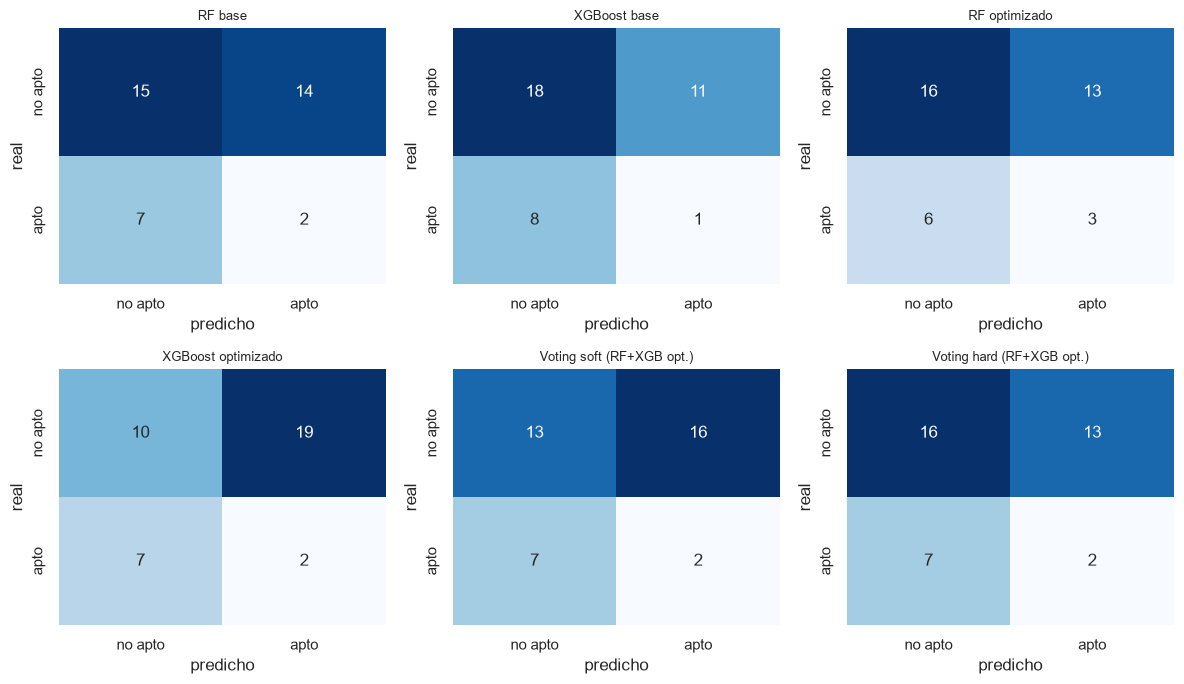

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(12, 7))
for ax, (nombre, p) in zip(axs.ravel(), preds.items()):
    sns.heatmap(evaluate.matriz_confusion(y, p), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['no apto', 'apto'], yticklabels=['no apto', 'apto'])
    ax.set_title(nombre, fontsize=9); ax.set_xlabel('predicho'); ax.set_ylabel('real')
plt.tight_layout(); plt.savefig(FIG / 'confusion_final.png', dpi=120); plt.show()

## 5. Curvas de aprendizaje
F1 promedio por pliegue (leave-one-id-out) al crecer el set de entrenamiento. En pliegues sin positivos (p. ej. el ID 4) el F1 es 0, lo que baja el promedio.

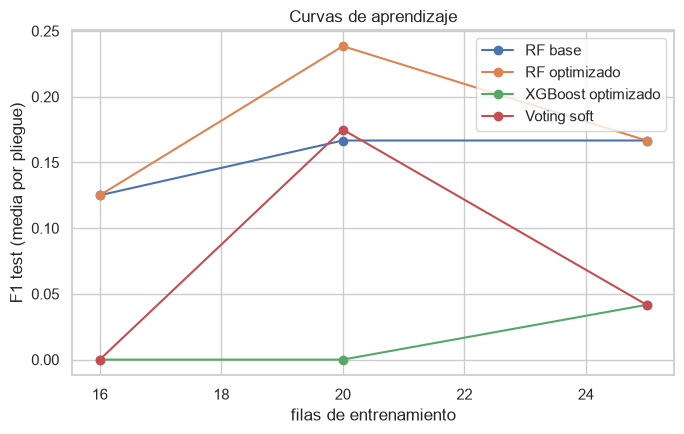

In [7]:
candidatos = {'RF base': base['random_forest'],
              'RF optimizado': optimize.construir('random_forest', bp_rf, y),
              'XGBoost optimizado': optimize.construir('xgboost', bp_xgb, y),
              'Voting soft': optimize.crear_ensamble(bp_rf, bp_xgb, y, 'soft')}
fig, ax = plt.subplots(figsize=(7, 4.5))
for nombre, m in candidatos.items():
    tam, _, test = learning_curve(m, X, y, groups=grupos, cv=LeaveOneGroupOut(), scoring='f1',
                                  train_sizes=np.linspace(0.3, 1.0, 5), shuffle=True, random_state=42)
    ax.plot(tam, test.mean(axis=1), 'o-', label=nombre)
ax.set_xlabel('filas de entrenamiento'); ax.set_ylabel('F1 test (media por pliegue)'); ax.legend()
ax.set_title('Curvas de aprendizaje'); plt.tight_layout(); plt.savefig(FIG / 'curvas_aprendizaje.png', dpi=120); plt.show()

## 6. Selección del modelo y persistencia

In [8]:
ganador_nombre = tabla['f1'].idxmax()
print('Ganador por F1 CV:', ganador_nombre, '| F1 =', tabla.loc[ganador_nombre, 'f1'])
constructores = {
    'RF base': lambda: train.crear_modelos(y)['random_forest'],
    'XGBoost base': lambda: train.crear_modelos(y)['xgboost'],
    'RF optimizado': lambda: optimize.construir('random_forest', bp_rf, y),
    'XGBoost optimizado': lambda: optimize.construir('xgboost', bp_xgb, y),
    'Voting soft (RF+XGB opt.)': lambda: optimize.crear_ensamble(bp_rf, bp_xgb, y, 'soft'),
    'Voting hard (RF+XGB opt.)': lambda: optimize.crear_ensamble(bp_rf, bp_xgb, y, 'hard'),
}
mejor = constructores[ganador_nombre]().fit(X, y)
ruta = train.guardar_modelo(mejor, 'best_tabular_model')
print('Guardado en', ruta)

Ganador por F1 CV: RF optimizado | F1 = 0.24


Guardado en C:\Users\rafa\Desktop\apple-vision-chile\models\best_tabular_model.joblib


In [9]:
params_log = {'modelo_ganador': ganador_nombre, 'features': ','.join(FEATURES_SUPERVISADO),
              'cv': 'leave-one-id-out', 'n_trials': N_TRIALS,
              **{f'rf_{k}': v for k, v in bp_rf.items()}, **{f'xgb_{k}': v for k, v in bp_xgb.items()}}
evaluate.registrar('best_tabular_model', params_log,
                   {f'cv_{k}': v for k, v in resultados[ganador_nombre].items()},
                   {'optuna': FIG / 'optuna_historia.png', 'curvas': FIG / 'curvas_aprendizaje.png',
                    'confusion': FIG / 'confusion_final.png'}, ruta)
print('Run registrado en MLflow (experimento applevision-calidad).')

Run registrado en MLflow (experimento applevision-calidad).


## 7. Importancia de características (modelo guardado)

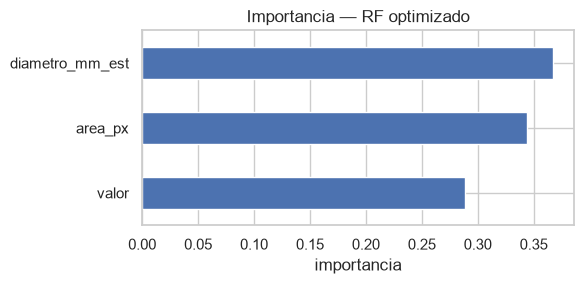

In [10]:
modelo = joblib.load('../models/best_tabular_model.joblib')
if hasattr(modelo, 'estimators_'):   # VotingClassifier: promedio de los estimadores
    imps = np.mean([e.feature_importances_ for e in modelo.estimators_], axis=0)
else:
    imps = modelo.feature_importances_
imp = pd.Series(imps, index=FEATURES_SUPERVISADO).sort_values()
ax = imp.plot.barh(figsize=(6, 3), title=f'Importancia — {ganador_nombre}'); ax.set_xlabel('importancia')
plt.tight_layout(); plt.savefig(FIG / 'importancia_final.png', dpi=120); plt.show()

## 8. Tabla comparativa de F1

In [11]:
comp = tabla[['f1', 'precision', 'recall', 'accuracy']].copy()
comp.index.name = 'modelo'
print(comp.to_string())
comp

                              f1  precision  recall  accuracy
modelo                                                       
RF base                    0.160      0.125   0.222     0.447
XGBoost base               0.095      0.083   0.111     0.500
RF optimizado              0.240      0.188   0.333     0.500
XGBoost optimizado         0.133      0.095   0.222     0.316
Voting soft (RF+XGB opt.)  0.148      0.111   0.222     0.395
Voting hard (RF+XGB opt.)  0.167      0.133   0.222     0.474


,f1,precision,recall,accuracy
modelo,,,,
RF base,0.160,0.125,0.222,0.447
XGBoost base,0.095,0.083,0.111,0.500
RF optimizado,0.240,0.188,0.333,0.500
XGBoost optimizado,0.133,0.095,0.222,0.316
Voting soft (RF+XGB opt.),0.148,0.111,0.222,0.395
Voting hard (RF+XGB opt.),0.167,0.133,0.222,0.474


## 9. Conclusiones
- El F1 de los modelos optimizados y del ensamble está sesgado al alza: los hiperparámetros se eligieron sobre los mismos 4 pliegues. Una mejora frente a los modelos base puede ser en buena parte sobreajuste a la búsqueda.
- Con 4 manzanas y etiquetas simuladas, ninguna diferencia entre modelos es concluyente. `best_tabular_model.joblib` es el mejor *según esta validación*, no un modelo listo para producción.
- Para decidir de verdad: más partidas/videos, recalibrar `px_por_mm`, etiquetas reales de calidad y una validación anidada o un set de prueba externo.